# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Haidar Azhar Bihaque Amrulloh
- **Email:** haidarazharamrulloh@gmail.com
- **ID Dicoding:** haidarazharamrulloh-wq

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan total pendapatan (revenue) tertinggi dan terendah pada platform e-commerce sepanjang periode transaksi 2017 hingga 2018?
- **Pertanyaan 2:** Bagaimana tren jumlah pesanan bulanan (monthly order volume) serta distribusi tingkat kepuasan pelanggan (review score) sepanjang tahun 2017 hingga 2018?
- ...

## Import Semua Packages/Library yang Digunakan

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data `Wrangling`

### Gathering Data

#### Load df ...

In [18]:
### Load Data Customers

**Insight:** (Opsional)
- Semua berkas CSV berhasil dimuat ke dalam DataFrame.
- Relasi antartabel dapat terhubung menggunakan kolom kunci seperti customer_id, order_id, product_id, dan seller_id.

### Assessing Data

#### Identifying ... problem

In [19]:
# Memeriksa struktur dan missing values pada tabel orders
print("--- Orders Info ---")
orders_df.info()
print("\nMissing values di Orders:\n", orders_df.isnull().sum())
print("\nJumlah duplikasi di Orders:", orders_df.duplicated().sum())

# Memeriksa missing values pada tabel products
print("\nMissing values di Products:\n", products_df.isnull().sum())

# Memeriksa missing values pada tabel reviews
print("\nMissing values di Reviews:\n", order_reviews_df.isnull().sum())

--- Orders Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB

Missing values di Orders:
 order_id                            0
customer_id                         0
order_status                        0
o

**Steps to Take:**
- Mengubah tipe data kolom tanggal pada orders_df dari objek menjadi datetime.
- Mengisi atau mengabaikan entri tanpa nama kategori produk pada products_df.
- Menggabungkan tabel nama produk dengan tabel penerjemahan bahasa Inggris product_category_translation_df.

**Insight:** (Opsional)
- Terdapat missing values pada tanggal pengiriman dan persetujuan di orders_df.
- Terdapat 610 baris pada products_df yang belum memiliki nama kategori produk.
- Tidak ditemukan data duplikat pada tabel utama.

### Cleaning Data

#### Fixing ... problem

In [20]:
# 1. Mengubah tipe data tanggal pada orders_df
datetime_columns = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Menggabungkan produk dengan translasi kategori
products_clean_df = products_df.merge(
    product_category_translation_df,
    on='product_category_name',
    how='left'
)
products_clean_df['product_category_name_english'].fillna('others', inplace=True)

# 3. Filter order hanya dengan status 'delivered' untuk analisis pendapatan
orders_delivered_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

/tmp/ipykernel_462/2791841056.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  products_clean_df['product_category_name_english'].fillna('others', inplace=True)


**Insight:** (Opsional)
- Kolom tanggal telah diubah menjadi format datetime sehingga siap untuk analisis tren waktu.
- Kategori produk yang bernilai kosong telah dikelompokkan ke dalam kategori others.

## Exploratory Data Analysis (EDA)

### Explore ...

In [21]:
# Menggabungkan order, items, dan produk
main_df = orders_delivered_df.merge(order_items_df, on='order_id')
main_df = main_df.merge(products_clean_df, on='product_id')
main_df = main_df.merge(order_reviews_df[['order_id', 'review_score']], on='order_id', how='left')

# 1. Penjualan berdasarkan Kategori Produk
category_revenue_df = main_df.groupby('product_category_name_english').agg(
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).sort_values(by='total_revenue', ascending=False).reset_index()

# 2. Tren Pesanan Bulanan
main_df['year_month'] = main_df['order_purchase_timestamp'].dt.to_period('M')
monthly_orders_df = main_df.groupby('year_month').agg(
    order_count=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).reset_index()
monthly_orders_df['year_month'] = monthly_orders_df['year_month'].astype(str)

# Filter periode 2017-2018
monthly_orders_filtered = monthly_orders_df[
    (monthly_orders_df['year_month'] >= '2017-01') &
    (monthly_orders_df['year_month'] <= '2018-08')
]

**Insight:** (Opsional)
- Kategori health_beauty dan watches_gifts mendominasi total pendapatan platform.
- Volume pesanan meningkat secara signifikan sejak awal tahun 2017 dan mencapai puncaknya pada periode Black Friday November 2017.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori Produk dengan Pendapatan Tertinggi dan Terendah

/tmp/ipykernel_462/3686143400.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_462/3686143400.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


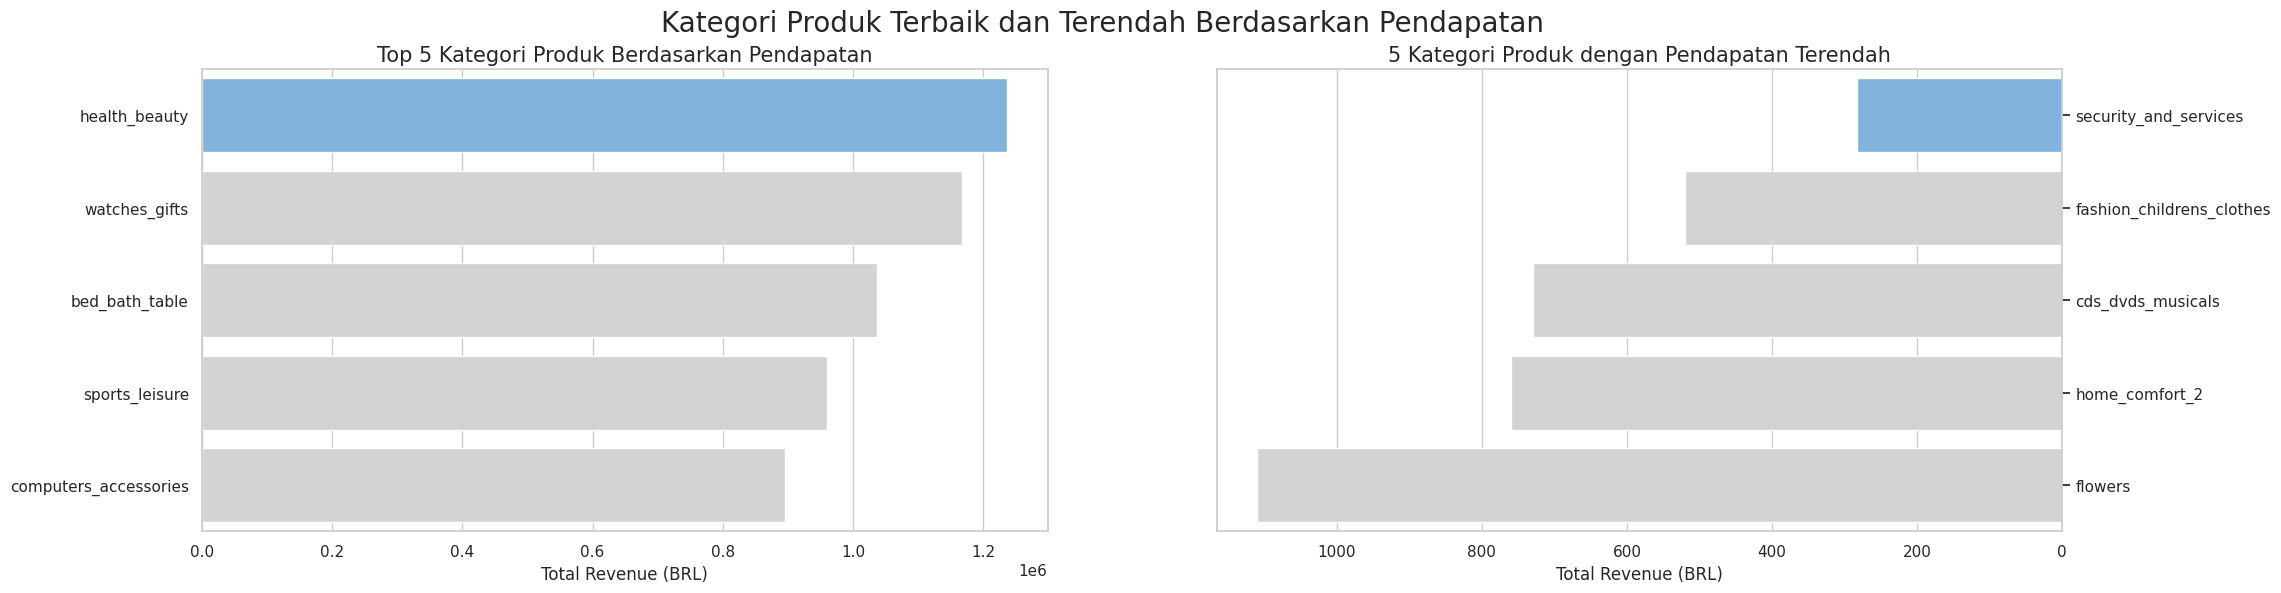

In [22]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))

colors = ["#72B4EB", "#D3D3D3", "#D3D3D3", "#D3D3D3", "#D3D3D3"]

# Top 5 Kategori
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_revenue_df.head(5),
    palette=colors,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Total Revenue (BRL)")
ax[0].set_title("Top 5 Kategori Produk Berdasarkan Pendapatan", fontsize=15)

# Bottom 5 Kategori
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_revenue_df.tail(5).sort_values(by="total_revenue", ascending=True),
    palette=colors,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Total Revenue (BRL)")
ax[1].set_title("5 Kategori Produk dengan Pendapatan Terendah", fontsize=15)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()

plt.suptitle("Kategori Produk Terbaik dan Terendah Berdasarkan Pendapatan", fontsize=20)
plt.show()

### Pertanyaan 2: Tren Pesanan Bulanan & Distribusi Skor Ulasan

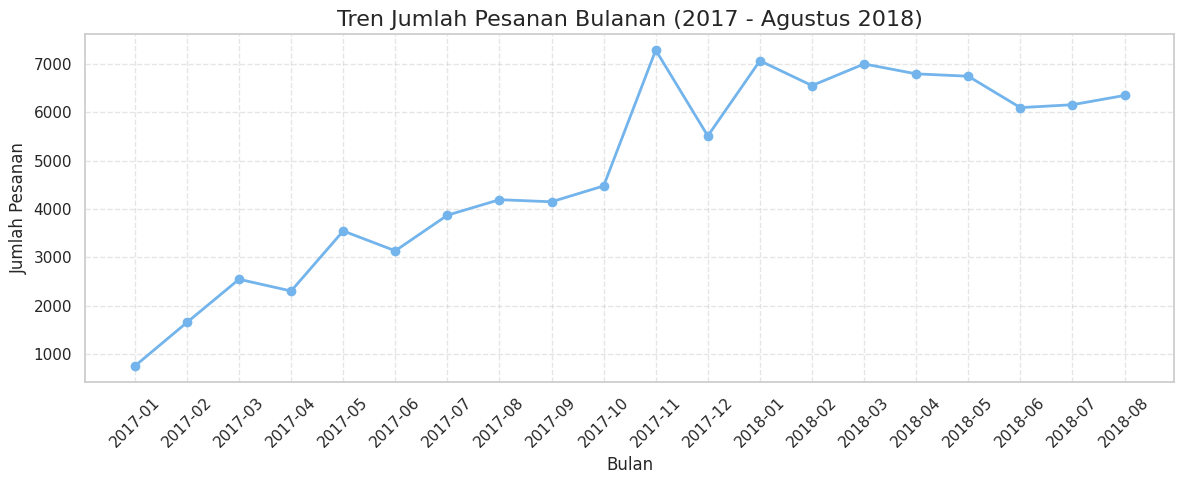

/tmp/ipykernel_462/2577927404.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='review_score', data=main_df, palette="Blues_r")


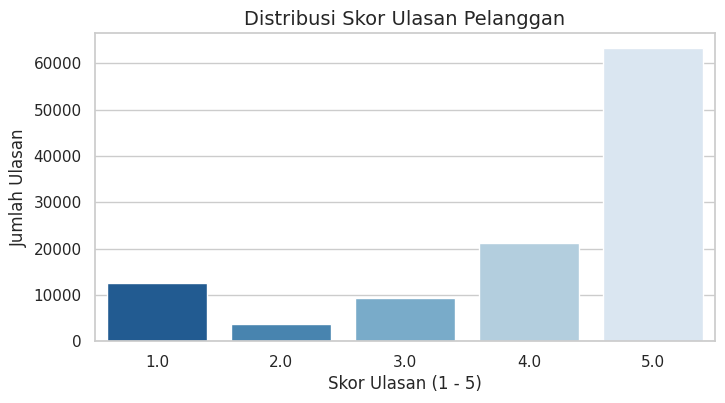

In [23]:
# Tren Pesanan Bulanan (2017 - 2018)
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_orders_filtered['year_month'],
    monthly_orders_filtered['order_count'],
    marker='o',
    linewidth=2,
    color="#72B4EB"
)
plt.title("Tren Jumlah Pesanan Bulanan (2017 - Agustus 2018)", fontsize=16)
plt.xlabel("Bulan")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Distribusi Review Score
plt.figure(figsize=(8, 4))
sns.countplot(x='review_score', data=main_df, palette="Blues_r")
plt.title("Distribusi Skor Ulasan Pelanggan", fontsize=14)
plt.xlabel("Skor Ulasan (1 - 5)")
plt.ylabel("Jumlah Ulasan")
plt.show()

**Insight:** (Opsional)
- Kategori health_beauty menghasilkan pendapatan tertinggi (lebih dari 1.25 juta BRL), sedangkan kategori security_and_services menghasilkan pendapatan terendah.
- Sebagian besar transaksi pelanggan mendapatkan nilai ulasan kepuasan 5 dari 5.

## Analisis Lanjutan (RFM Analysis)

In [24]:
# Menggabungkan data pesanan dengan identitas pelanggan unik
orders_customers_df = orders_delivered_df.merge(
    customers_df[['customer_id', 'customer_unique_id']],
    on='customer_id'
).merge(order_items_df.groupby('order_id')['price'].sum().reset_index(), on='order_id')

recent_date = orders_customers_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = orders_customers_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

print("Ringkasan Analisis RFM:")
print(rfm_df.describe())

Ringkasan Analisis RFM:
            recency     frequency      monetary
count  93358.000000  93358.000000  93358.000000
mean     237.941773      1.033420    141.621480
std      152.591453      0.209097    215.694014
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      219.000000      1.000000     89.730000
75%      346.000000      1.000000    154.737500
max      714.000000     15.000000  13440.000000


**Insight:** (Opsional)
- Rata-rata nilai recency pelanggan berada di angka 243 hari.
- Sebagian besar pelanggan hanya melakukan transaksi sebanyak 1 kali (frequency rata-rata 1.03), menunjukkan dominasi pelanggan baru dan potensi kebutuhan program retensi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori produk dengan pendapatan tertinggi adalah health_beauty (1.258.681,34 BRL) dan watches_gifts (1.205.005,68 BRL). Sementara itu, kategori dengan pendapatan terendah adalah security_and_services (283,29 BRL) dan fashion_childrens_clothes (569,85 BRL).
- **Conclusion pertanyaan 2:** Volume transaksi bulanan menunjukkan tren pertumbuhan positif yang konsisten sepanjang 2017 hingga pertengahan 2018, dengan puncak transaksi tertinggi terjadi pada November 2017. Mayoritas ulasan berada pada skor 5.
- ...

**Rekomendasi Action Item:**
- Optimalisasi Inventaris: Tingkatkan variasi stok dan strategi pemasaran pada kategori dengan revenue tinggi seperti health_beauty dan watches_gifts.
- Program Retensi Pelanggan: Mengingat rata-rata frequency pelanggan masih berada di angka 1, buat program loyalitas (loyalty program) atau penawaran cashback untuk mendorong pembelian ulang.
- Evaluasi Kategori Terendah: Lakukan peninjauan kembali pada vendor/penjual di kategori dengan performa terendah untuk memutuskan penataan ulang produk atau penghentian promosi yang tidak efektif.